In [1]:
from sympy import *
init_printing(use_latex=True)
from scipy.integrate import solve_ivp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnchoredText
from matplotlib.patches import Circle

%matplotlib widget

In [2]:
#SYMBOLIC EXPRESSION

t,r,theta,phi = symbols('t r theta phi', cls = Function)
td,rd,thetad,phid = symbols('td rd thetad phid', cls = Function)
lam = symbols('lam')
m = symbols('m', positive = True)

t = t(lam)
r = r(lam)
theta = theta(lam)
phi = phi(lam)

td = td(lam)
rd = rd(lam)
thetad = thetad(lam)
phid = phid(lam)

tdd = -(m/(r*(r - 2*m)) * td * rd)
rdd = -(m*(r-2*m)/r**3*td**2 - m/(r*(r-2*m))*rd**2 - 
          (r-2*m)*thetad**2 - (r-2*m)*sin(theta)**2*phid**2)
thetadd = -(2/r*thetad*rd - sin(2*theta)/2*phid**2)
phidd =  -(2/r*rd*phid + 2*cot(theta)*thetad*phid)


In [3]:
#DEFINING THE METRIC
m_val = 5

metric_t = -(1-2*m/r)
metric_r = 1/(1-2*m/r)
metric_theta = r**2
metric_phi = r**2*sin(theta)**2

metric = np.array([metric_t, metric_r, 
          metric_theta, metric_phi])

In [4]:
#TRANSLATING SYMBOLIC TO NUMERICAL
dd_m_sub = [e.subs(m,m_val) for e in [tdd,rdd,thetadd,phidd]]
g_m_sub = [e.subs(m,m_val) for e in metric]

f_dd = lambdify(
    (t,r,theta,phi,td,rd,thetad,phid),
    dd_m_sub,
    'numpy'
)

metric_lam = lambdify((r, theta), g_m_sub, 'numpy')

def null_curve(r_,th_, ders):
    g = np.array(metric_lam(r_,th_))
    v = np.array(ders)
    dt = np.sqrt(-(np.sum(g[1:]*v**2)/g[0]))
    return dt

def geod(lam,coord):
    [t,r,theta,phi] = coord[:4]
    v = coord[4:]
    return [ *v, *f_dd(*coord)]

In [ ]:
def horizon(lam, y):
    return y[1] - 2*m_val*1.001


def solve_geod(t0,r0,theta0,phi0,rd0,thetad0,phid0, reverse = 1, lam_max = 1000, n_lam = 1000):

    td0 = null_curve(r0, theta0, [rd0,thetad0,phid0])
    coord0 = [t0,r0,theta0,phi0,td0,rd0,thetad0,phid0]

    lam0 = 0
    lam_space=np.linspace(lam0,reverse*lam_max,n_lam)

    horizon.terminal = True

    sol = solve_ivp(
        geod,
        [lam_space[0], lam_space[-1] ],
        coord0,
        method='DOP853', #method to 8th order
        rtol=1e-10, atol=1e-12, #smaller tolerance for best accuracy
        t_eval = lam_space,
        events = horizon
    )

    t_a,r_a,th_a,phi_a,td_a,rd_a,thd_a,phid_a = sol.y

    z_a = r_a * np.sin(th_a) * np.cos(phi_a) 
    x_a = r_a * np.sin(th_a) * np.sin(phi_a)

    y_a = r_a * -np.cos(th_a)

    return [x_a,y_a,z_a,t_a]


geo_vec = np.vectorize(solve_geod, otypes=[object])


In [18]:
#Plotting
def plotter_3d(geos):
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')

    u,v = np.mgrid[0:2*np.pi:60j, 0:np.pi:30j]
    R = 2*m_val
    ax.plot_surface(
        R*np.cos(u)*np.sin(v),
        R*np.sin(u)*np.sin(v),
        R*np.cos(v),
        color = 'grey'
    )

    for j in geos:
        change_idx = np.where(j[2][:-1] * j[2][1:] < 0)[0]
        if  len(change_idx)>2:
            ax.plot(j[1],j[2],j[0], color = 'red') #photon ring
        else:
            if len(change_idx) == 2:
               ax.plot(j[1],j[2],j[0], color = 'orange') #lensing ring
            else:  
                ax.plot(j[1],j[2],j[0], color = 'lightblue') #direct

    """
    for j in geos:
        b = np.linalg.norm([j[0][0],j[1][0]])
        if  5.19*m_val < b  and b < 5.23*m_val:
            ax.plot(j[1],j[2],j[0], color = 'red')
        else:
            if 5.02*m_val < b  and b < 6.17*m_val:
                ax.plot(j[1],j[2],j[0], color = 'orange')
            else:
                if b <= 5.02*m_val:
                    ax.plot(j[1],j[2],j[0], color = 'lightgreen')
                else:  ax.plot(j[1],j[2],j[0], color = 'lightblue')
    """

    ax.set_xlim(-30,30)
    ax.set_ylim(-30,30)
    ax.set_zlim(-30,30)

    ax.set_box_aspect((1,1,1))

    ax.set_xlabel('x')
    ax.set_ylabel('z')
    ax.set_zlabel('y')

    return 


In [35]:
#Black hole
m_val = 5

#SCREEN (coordinates on screen plane)
screen_dist = -5000

r_screen = np.linspace(3.8,4.2,10)*m_val
r_screen_out = np.linspace(5,10,3)*m_val
r_screen = np.concatenate([r_screen,r_screen_out])
rho = np.linspace(0,2*np.pi,5)

R,RHO = np.meshgrid(r_screen,rho)

X = R * np.cos(RHO)
Y = R * np.sin(RHO)

#INITIAL COORDINATES IN SPACE
z0 = screen_dist
r0 = np.sqrt(Y**2 + X**2 + z0**2)
theta0 = np.pi/2 + np.arctan2(Y, np.hypot(z0,X))
phi0 = np.arctan2(X,z0)

t0 = 0

#INITIAL SPEEDS
zd0 = -10
yd0 = 0
xd0 = 0

rd0 = (1/r0)*(X*xd0 + Y*yd0 + z0*zd0)
phid0 = (z0*xd0 - X*zd0)/(X**2+z0**2)
thetad0 = (((X**2 + z0**2)*yd0 - Y*(X*xd0 + z0*zd0))/
           (np.sqrt(X**2 + z0**2)*(X**2+Y**2+z0**2)))


#Computing geodesics
geos = geo_vec(t0,r0,theta0,phi0,rd0,thetad0,phid0, reverse = -1, lam_max = 2000, n_lam = 3000)



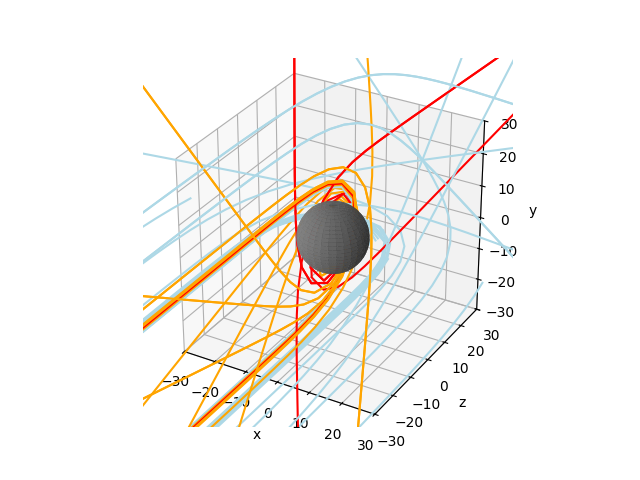

In [37]:
plotter_3d(geos.flat)

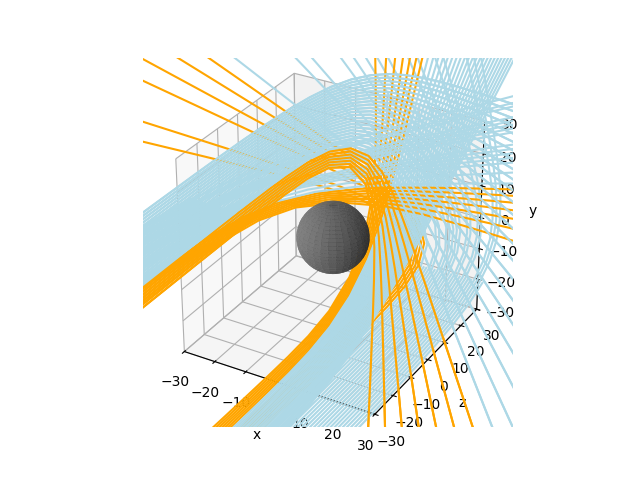

In [9]:
#Source position
xs = 1
ys = 1
zs = 10

phi_s = np.arctan2(xs,zs)

#FILTERING FOR RAYS HITTING THE SOURCE
tolerance = 100
geos_hit = []

for i in geos:
    for j in i:
        divs = ((j[0]-xs)**2 + (j[1]-ys)**2 + (j[2]-ys)**2)**0.5
        hit_terms = np.flatnonzero(divs<tolerance)
        if hit_terms.size:
            geos_hit.append(j)

plotter_3d(geos_hit)

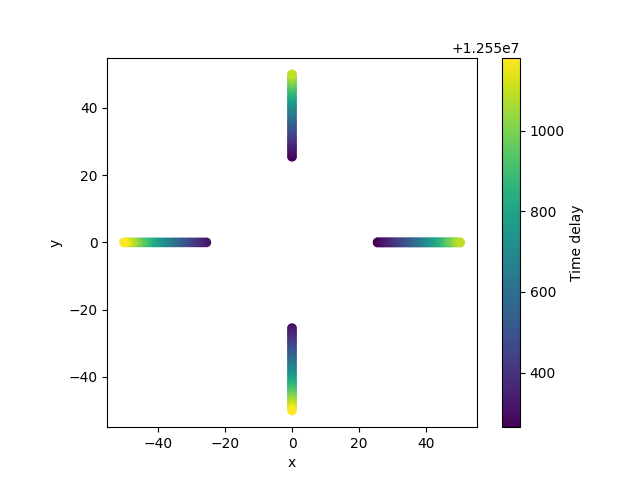

In [10]:
#Defining Time delay
def time_delay(xs,ys,zs,x0,y0,z0):
    phi_s = np.arctan2(xs,zs)
    phi_0 = np.arctan2(x0,z0)
    delta_phi = np.abs(phi_s-phi_0)
    b0 = np.linalg.norm([x0,y0])

    vec_o = np.array([x0,y0,z0])
    vec_s = np.array([xs,ys,zs])

    geom = np.linalg.norm(vec_o - vec_s)**2/2
    shap = np.log(np.linalg.norm(vec_o))
    az_comp = b0*delta_phi

    return geom-shap - az_comp

Td_surf = []
for i in geos_hit:
    x0 = i[0][0]
    y0 = i[1][0]
    z0 = i[2][0]
    Td_surf.append([x0,y0,time_delay(xs,ys,zs,x0,y0,z0)])

Td_surf = np.transpose(Td_surf)

fig = plt.figure()
plt.scatter(Td_surf[0], Td_surf[1], c=Td_surf[2], cmap="viridis")
plt.colorbar(label="Time delay")
plt.xlabel("x")
plt.ylabel("y")
plt.gca().set_aspect("equal")
plt.show()